In [81]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [82]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [83]:
df.shape

(7043, 21)

Understand The Dataset

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [85]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [86]:
df.describe(include="object")

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


Checking Missing values

In [87]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [88]:
df["TotalCharges"].value_counts().head()

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
Name: count, dtype: int64

In [89]:
df["TotalCharges"].astype(str).str.strip().eq("").sum()

np.int64(11)

Fix TotalCharges

In [90]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [91]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [92]:
df.dropna(subset=["TotalCharges"], inplace=True)

In [93]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Check duplicate rows

In [94]:
df.duplicated().sum()

np.int64(0)

In [95]:
df.drop_duplicates(inplace=True)

Remove customerID

In [96]:
df.drop("customerID", axis=1, inplace=True)

In [97]:
df.shape

(7032, 20)

Check target variable

In [98]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

Visualization

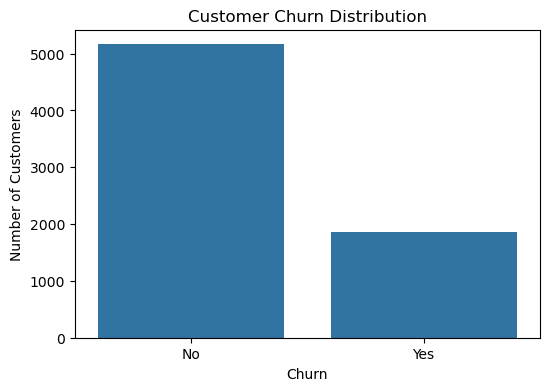

In [99]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [100]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


Convert Churn to 0 and 1

In [101]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [102]:
df["Churn"].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

# Data visualization / EDA

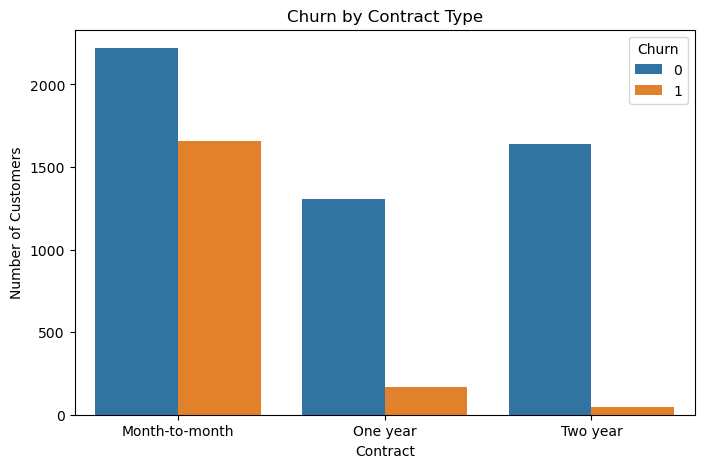

In [103]:
# Churn vs Contract
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")

plt.show()

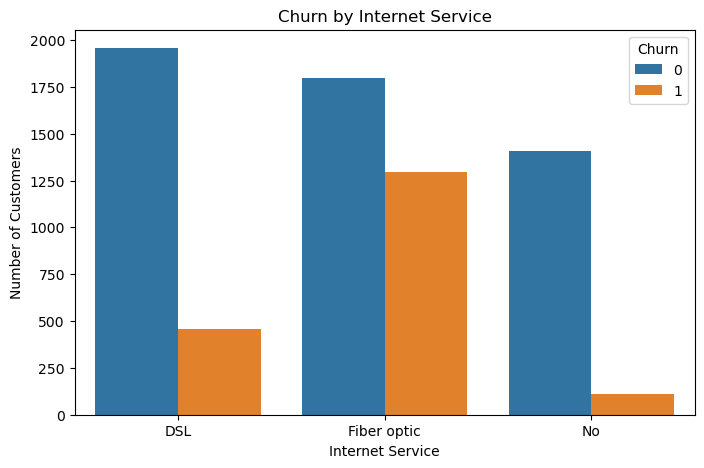

In [104]:
# Churn vs Internet Service
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

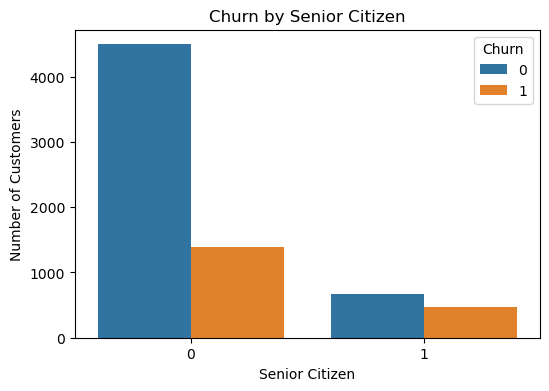

In [105]:
# Churn vs Senior Citizen
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Churn by Senior Citizen")
plt.xlabel("Senior Citizen")
plt.ylabel("Number of Customers")

plt.show()

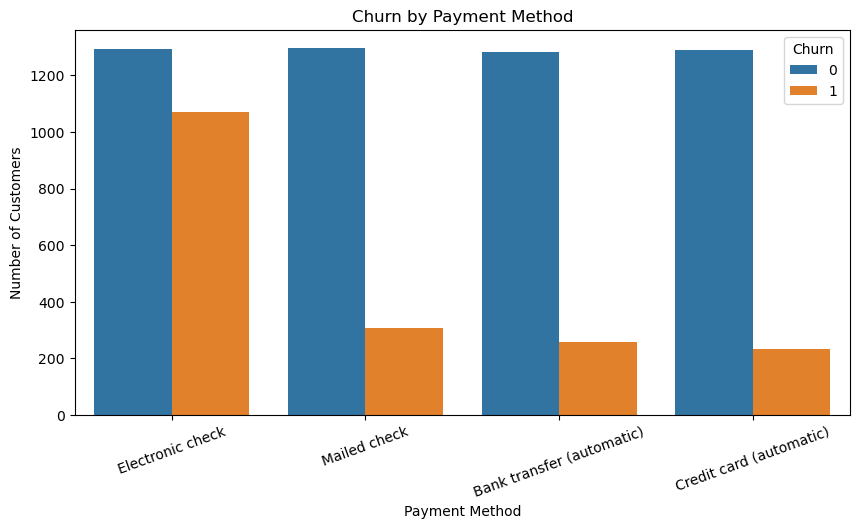

In [106]:
# Churn vs Payment Method
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

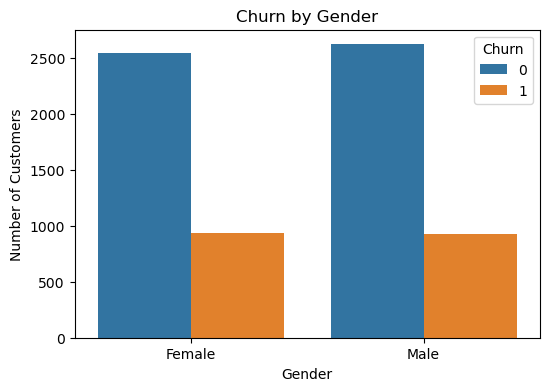

In [107]:
# Churn vs Gender
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

plt.title("Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

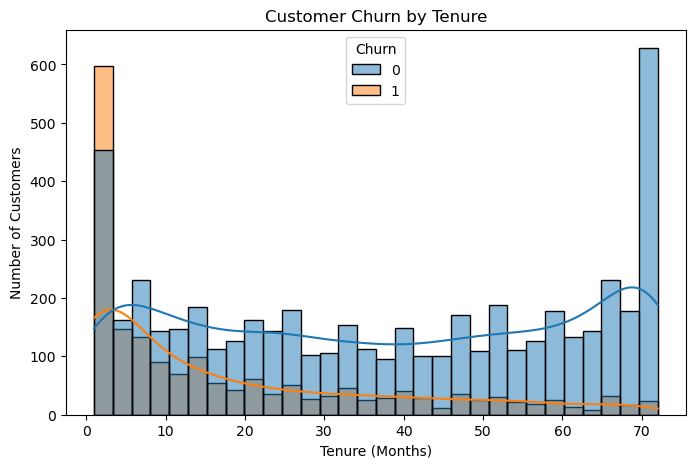

In [108]:
# Churn vs Tenure
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

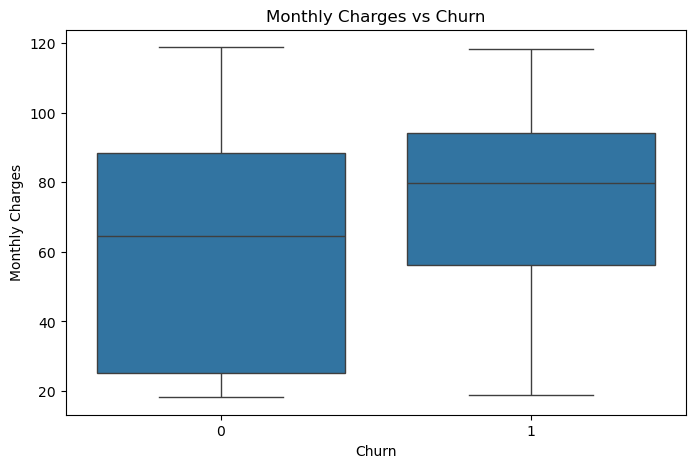

In [109]:
# Churn vs Monthly Charges
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

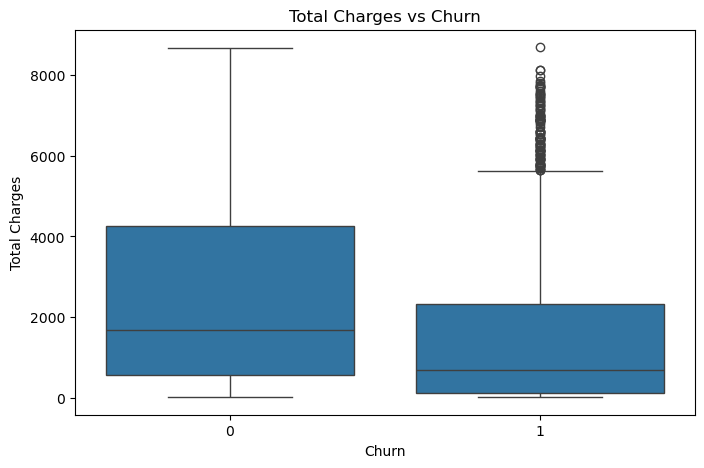

In [110]:
# Churn vs Total Charges
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

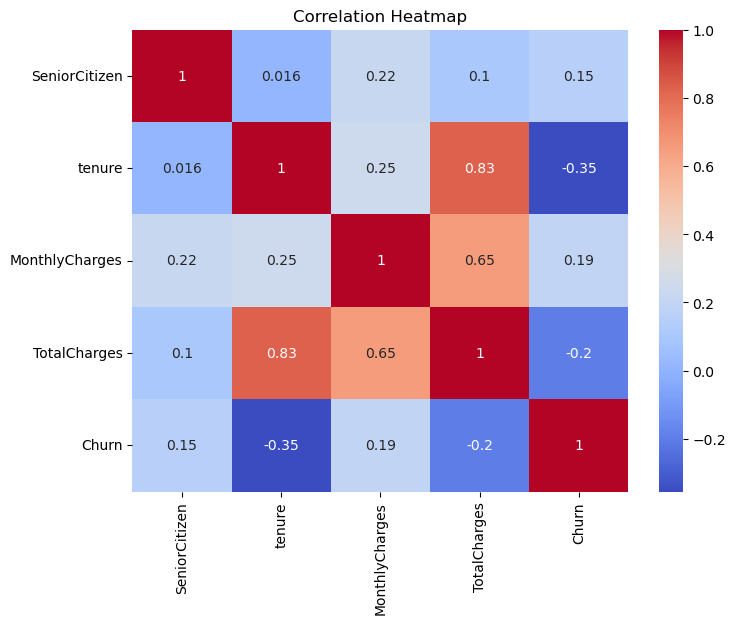

In [111]:
# Correlation heatmap
plt.figure(figsize=(8, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

# Prepare X and y

In [112]:
y = df["Churn"]


In [113]:
X = df.drop("Churn", axis=1)

In [114]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [115]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

# Identify numerical and categorical columns

In [116]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

In [117]:
print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


# Train/Test Split

In [118]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [119]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# Model 1 — Logistic Regression

In [120]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)



In [121]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

In [122]:
grid_search = GridSearchCV(
    logistic_model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__solver': 'liblinear'}
Best F1 Score: 0.5964817699878876


In [123]:
best_logistic_model = grid_search.best_estimator_
y_pred_tuned = best_logistic_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

Accuracy: 0.8038379530916845
Precision: 0.6484848484848484
Recall: 0.5721925133689839
F1 Score: 0.6079545454545454


In [124]:
y_probability = best_logistic_model.predict_proba(X_test)[:, 1]

In [125]:
print(y_probability[:10])

[0.0176903  0.59159696 0.00486285 0.20151669 0.10198035 0.47230556
 0.02649485 0.16537551 0.67925884 0.01567172]


In [126]:
# logistic_model.fit(
#     X_train,
#     y_train
# )

In [127]:
# y_pred = logistic_model.predict(X_test)

In [128]:
# accuracy_score(y_test, y_pred)

# Model 2 — Decision Tree

In [129]:
decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

In [130]:
decision_tree.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', DecisionTreeClassifier(random_state=42))])

In [131]:
y_pred_dt = decision_tree.predict(X_test)

In [132]:
accuracy_score(
    y_test,
    y_pred_dt
)

0.7306325515280739

# Model 3 — Random Forest

In [133]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [134]:
random_forest.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [135]:
y_pred_rf = random_forest.predict(X_test)

In [136]:
accuracy_score(
    y_test,
    y_pred_rf
)

0.7896233120113717

# Model 4 — KNN

In [137]:
knn = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            KNeighborsClassifier(
                n_neighbors=5
            )
        )
    ]
)

In [138]:
knn.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', KNeighborsClassifier())])

In [139]:
y_pred_knn = knn.predict(X_test)

In [140]:
accuracy_score(
    y_test,
    y_pred_knn
)

0.7604832977967306

# Model 5 — SVM

In [141]:
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            SVC(
                probability=True,
                random_state=42
            )
        )
    ]
)

In [142]:
svm_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', SVC(probability=True, random_state=42))])

In [143]:
y_pred_svm = svm_model.predict(X_test)

In [144]:
accuracy_score(
    y_test,
    y_pred_svm
)

0.7917555081734187

# Model 6 — Gradient Boosting

In [145]:
gradient_boosting = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)

In [146]:
gradient_boosting.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('model', GradientBoostingClassifier(random_state=42))])

In [147]:
y_pred_gb = gradient_boosting.predict(X_test)

In [148]:
accuracy_score(
    y_test,
    y_pred_gb
)

0.7960199004975125

# Compare all models automatically

In [149]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "KNN": knn,
    "SVM": svm_model,
    "Gradient Boosting": gradient_boosting
}

In [150]:
models = {
    "Tuned Logistic Regression": best_logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "KNN": knn,
    "SVM": svm_model,
    "Gradient Boosting": gradient_boosting
}

print("Models ready for comparison:")
print(list(models.keys()))

Models ready for comparison:
['Tuned Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM', 'Gradient Boosting']


In [160]:
# results = []

# for name, model in models.items():

#     model.fit(X_train, y_train)

#     y_pred = model.predict(X_test)

#     y_probability = model.predict_proba(X_test)[:, 1]

#     results.append({
#         "Model": name,
#         "Accuracy": accuracy_score(y_test, y_pred),
#         "Precision": precision_score(y_test, y_pred),
#         "Recall": recall_score(y_test, y_pred),
#         "F1 Score": f1_score(y_test, y_pred),
#         "ROC AUC": roc_auc_score(y_test, y_probability)
#     })

results = []

for name, model in models.items():

    # Fit using training data only
    model.fit(X_train, y_train)

    # Predict churn class and churn probability
    y_pred = model.predict(X_test)
    y_probability = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(
            y_test, y_probability
        )
    })

results_df = pd.DataFrame(results)

# Show best models by F1 score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("Updated Model Comparison:")
display(results_df.round(4))

Updated Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Tuned Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359
1,Gradient Boosting,0.7960,0.6408,0.5294,0.5798,0.8385
2,KNN,0.7605,0.5468,0.5775,0.5618,0.7791
3,SVM,0.7918,0.6401,0.4947,0.5581,0.7886
4,Random Forest,0.7896,0.6345,0.4920,0.5542,0.8140
5,Decision Tree,0.7306,0.4934,0.4973,0.4953,0.6565


FINAL TUNED LOGISTIC REGRESSION RESULTS
---------------------------------------------
Accuracy: 0.8038
Precision: 0.6485
Recall: 0.5722
F1 Score: 0.608
ROC-AUC: 0.8359

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



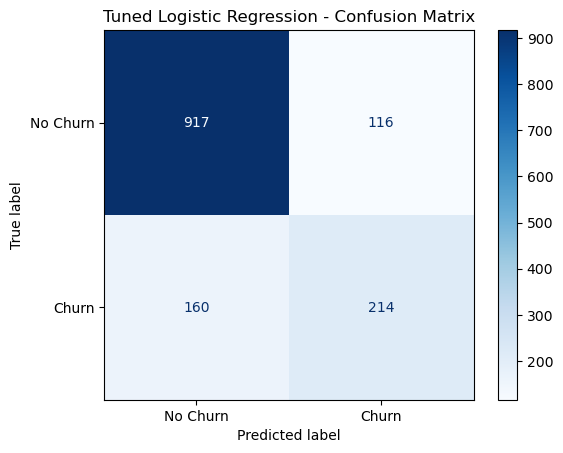

In [161]:
# Final evaluation of tuned Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Use the tuned model
final_model = best_logistic_model

# Predict on the held-out test set
y_pred_final = final_model.predict(X_test)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("FINAL TUNED LOGISTIC REGRESSION RESULTS")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_final), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_final), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_final), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_final), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_final), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Tuned Logistic Regression - Confusion Matrix")
plt.show()

In [152]:
results_df = pd.DataFrame(results)

In [153]:
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Tuned Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.835934
1,Decision Tree,0.730633,0.493369,0.497326,0.495340,0.656455
2,Random Forest,0.789623,0.634483,0.491979,0.554217,0.813999
3,KNN,0.760483,0.546835,0.577540,0.561769,0.779128
4,SVM,0.791756,0.640138,0.494652,0.558069,0.788553
5,Gradient Boosting,0.796020,0.640777,0.529412,0.579795,0.838524


In [154]:
results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Tuned Logistic Regression,0.803838,0.648485,0.572193,0.607955,0.835934
5,Gradient Boosting,0.796020,0.640777,0.529412,0.579795,0.838524
4,SVM,0.791756,0.640138,0.494652,0.558069,0.788553
2,Random Forest,0.789623,0.634483,0.491979,0.554217,0.813999
3,KNN,0.760483,0.546835,0.577540,0.561769,0.779128
1,Decision Tree,0.730633,0.493369,0.497326,0.495340,0.656455


# Visualize model comparison

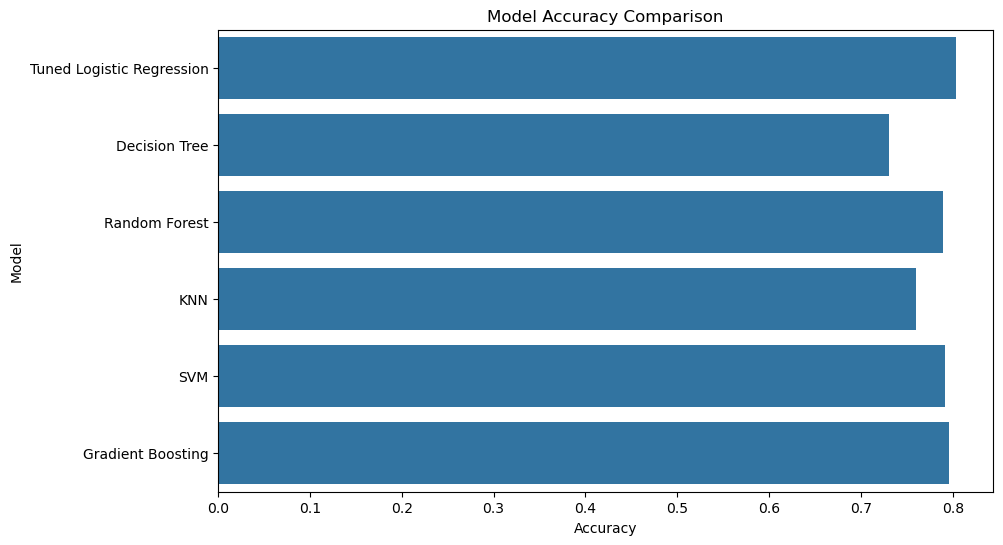

In [155]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")

plt.show()

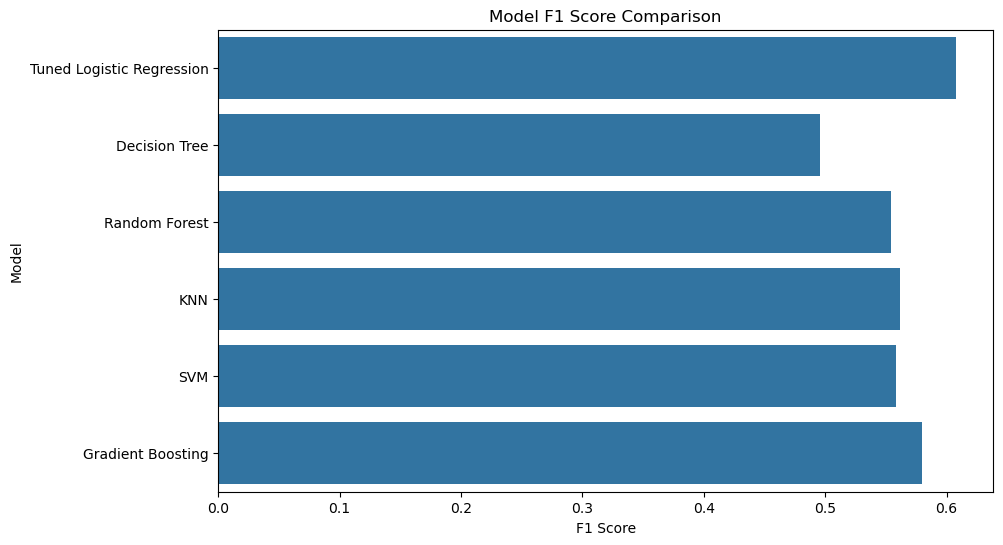

In [156]:
# For F1 Score Comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="F1 Score",
    y="Model"
)

plt.title("Model F1 Score Comparison")
plt.xlabel("F1 Score")
plt.ylabel("Model")

plt.show()

# Cross Validation for model improvement

In [157]:
df.shape

(7032, 20)

In [158]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [159]:
X=df.drop('Churn',axis=1)
y=df['Churn']

In [162]:
# Automatically select and save the best churn prediction model

import joblib
from pathlib import Path

# 1. Select the model with the highest F1 score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

print("Selected Model:", best_model_name)

# 2. Get the selected trained model
final_model = models[best_model_name]

# 3. Save the complete model pipeline
model_path = Path("churn_model.joblib")

joblib.dump(final_model, model_path)

print("\nModel saved successfully!")
print("Model name:", best_model_name)
print("Saved location:", model_path.resolve())

Selected Model: Tuned Logistic Regression

Model saved successfully!
Model name: Tuned Logistic Regression
Saved location: C:\Users\alekh\OneDrive\Desktop\FinalProject\Customer Churn\churn_model.joblib
